In [28]:
import pandas as pd#for tabular datas 
import numpy as np# for array handling
import scipy.stats as stats
import matplotlib.pyplot as plt#for visualization

In [29]:
from sklearn.datasets import load_iris#extracting inbuilt dataset from scikit-learn
#in short sklearn
iris = load_iris()#loading the data

In [30]:
iris

{'data': array([[5.1, 3.5, 1.4, 0.2],
        [4.9, 3. , 1.4, 0.2],
        [4.7, 3.2, 1.3, 0.2],
        [4.6, 3.1, 1.5, 0.2],
        [5. , 3.6, 1.4, 0.2],
        [5.4, 3.9, 1.7, 0.4],
        [4.6, 3.4, 1.4, 0.3],
        [5. , 3.4, 1.5, 0.2],
        [4.4, 2.9, 1.4, 0.2],
        [4.9, 3.1, 1.5, 0.1],
        [5.4, 3.7, 1.5, 0.2],
        [4.8, 3.4, 1.6, 0.2],
        [4.8, 3. , 1.4, 0.1],
        [4.3, 3. , 1.1, 0.1],
        [5.8, 4. , 1.2, 0.2],
        [5.7, 4.4, 1.5, 0.4],
        [5.4, 3.9, 1.3, 0.4],
        [5.1, 3.5, 1.4, 0.3],
        [5.7, 3.8, 1.7, 0.3],
        [5.1, 3.8, 1.5, 0.3],
        [5.4, 3.4, 1.7, 0.2],
        [5.1, 3.7, 1.5, 0.4],
        [4.6, 3.6, 1. , 0.2],
        [5.1, 3.3, 1.7, 0.5],
        [4.8, 3.4, 1.9, 0.2],
        [5. , 3. , 1.6, 0.2],
        [5. , 3.4, 1.6, 0.4],
        [5.2, 3.5, 1.5, 0.2],
        [5.2, 3.4, 1.4, 0.2],
        [4.7, 3.2, 1.6, 0.2],
        [4.8, 3.1, 1.6, 0.2],
        [5.4, 3.4, 1.5, 0.4],
        [5.2, 4.1, 1.5, 0.1],
  

In [31]:
df = pd.DataFrame(data=iris['data'], columns=iris.feature_names)
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [32]:
df['species']=pd.Series(iris.target).map({0: 'Setosa', 1: 'Versicolor', 2: 'Virginica'})
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Virginica
146,6.3,2.5,5.0,1.9,Virginica
147,6.5,3.0,5.2,2.0,Virginica
148,6.2,3.4,5.4,2.3,Virginica


In [33]:
df.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

In [34]:
Q1,Q2,Q3=df['sepal width (cm)'].quantile([0.25,0.50,0.75])
Q1,Q2,Q3

(2.8, 3.0, 3.3)

In [35]:
Q1,Q2,Q3=np.percentile(df['sepal width (cm)'], [25,50,75])
Q1,Q2,Q3

(2.8, 3.0, 3.3)

In [36]:
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print(lower_bound,upper_bound)

2.05 4.05


In [37]:
df[df.columns[:-1]].corr()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,-0.117570,0.871754,0.817941
sepal width (cm),-0.117570,1.000000,-0.428440,-0.366126
petal length (cm),0.871754,-0.428440,1.000000,0.962865
petal width (cm),0.817941,-0.366126,0.962865,1.000000


<Axes: xlabel='petal length (cm)', ylabel='petal width (cm)'>

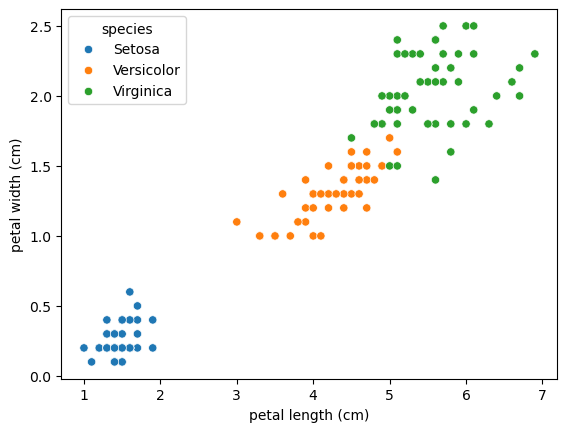

In [42]:
import seaborn as sns
sns.scatterplot(x=df['petal length (cm)'],y=df['petal width (cm)'],hue=df['species'])

In [11]:
outlier_data=df[(df['sepal width (cm)']<lower_bound) | (df['sepal width (cm)']>upper_bound)]
outlier_data

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
15,5.7,4.4,1.5,0.4,Setosa
32,5.2,4.1,1.5,0.1,Setosa
33,5.5,4.2,1.4,0.2,Setosa
60,5.0,2.0,3.5,1.0,Versicolor


In [12]:
normal_data=df[(df['sepal width (cm)']>lower_bound) & (df['sepal width (cm)']<upper_bound)]
normal_data

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Virginica
146,6.3,2.5,5.0,1.9,Virginica
147,6.5,3.0,5.2,2.0,Virginica
148,6.2,3.4,5.4,2.3,Virginica


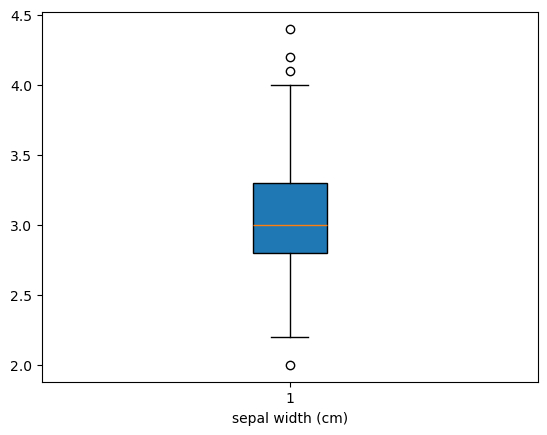

In [13]:
plt.boxplot(df['sepal width (cm)'], patch_artist=True)
plt.xlabel('sepal width (cm)')
plt.show()

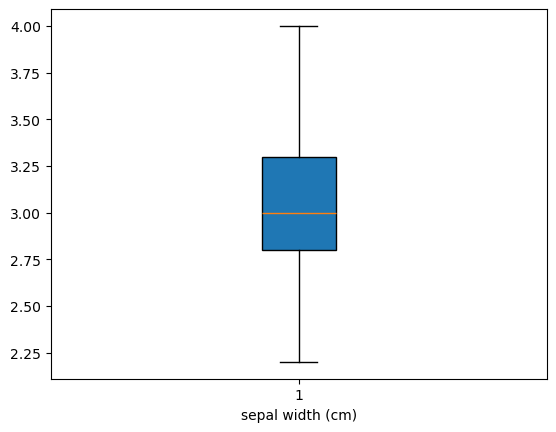

In [14]:
plt.boxplot(normal_data['sepal width (cm)'], patch_artist=True)
plt.xlabel('sepal width (cm)')
plt.show()

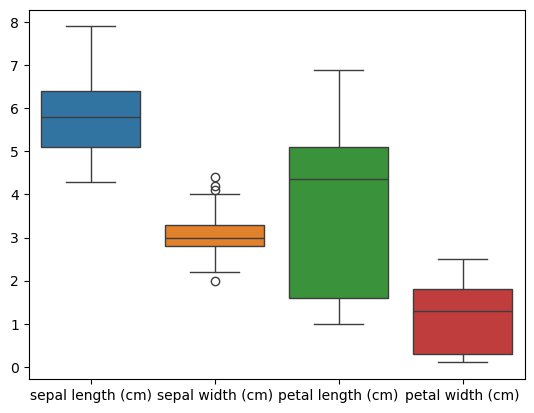

In [15]:
import seaborn as sns
sns.boxplot(df)
plt.show()

In [16]:
df.columns

Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'species'],
      dtype='object')

In [17]:
for i in df.columns:
    print(i)

sepal length (cm)
sepal width (cm)
petal length (cm)
petal width (cm)
species


In [18]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [19]:
for i,data in enumerate(df.columns):
    print(i,data)

0 sepal length (cm)
1 sepal width (cm)
2 petal length (cm)
3 petal width (cm)
4 species


In [20]:
df.columns[:-1]

Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)'],
      dtype='object')

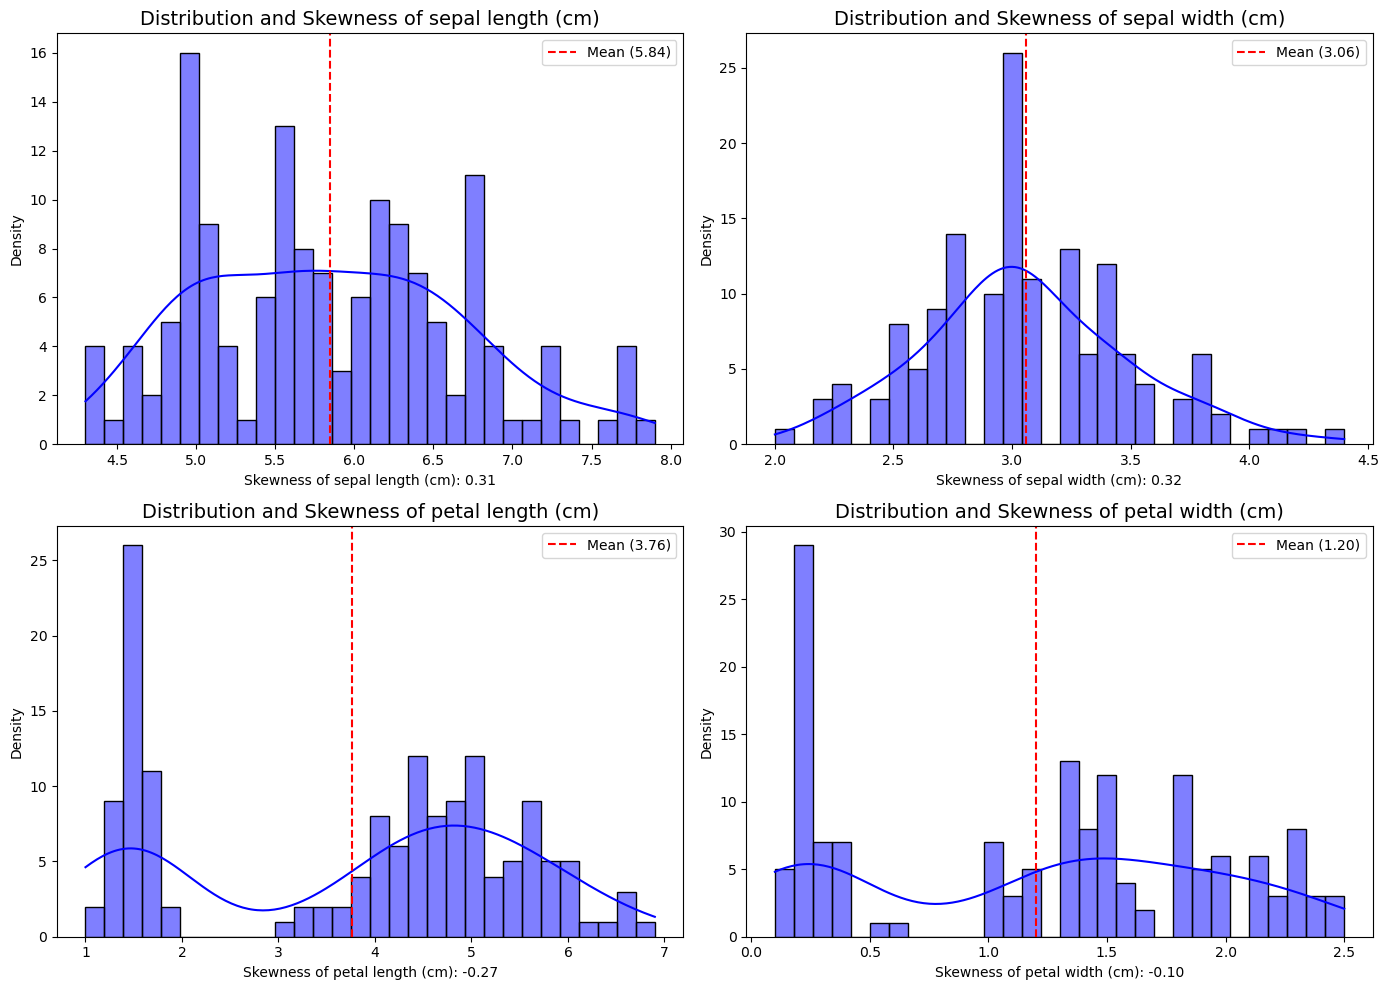

skewness of sepal length (cm):0.3117530585022963
skewness of sepal width (cm):0.31576710633893473
skewness of petal length (cm):-0.2721276664567214
skewness of petal width (cm):-0.10193420656560036


In [21]:
import seaborn as sns
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
for i, feature in enumerate(df.columns[:-1]):
    data = df[feature]
    skewness = stats.skew(data)
    sns.histplot(data, bins=30, kde=True, color='blue', ax=axes[i])
    axes[i].set_title(f'Distribution and Skewness of {feature}', fontsize=14)
    axes[i].set_xlabel(f'Skewness of {feature}: {skewness:.2f}')
    axes[i].set_ylabel('Density')
    axes[i].axvline(data.mean(), color='red', linestyle='--', label=f'Mean ({data.mean():.2f})')
    axes[i].legend()

plt.tight_layout()
plt.show()
for i in df.columns[:-1]:
    skewness = stats.skew(df[i])
    print(f'skewness of {i}:{skewness}')

In [22]:
df.shape

(150, 5)

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [24]:
sns.get_dataset_names()

URLError: <urlopen error [Errno 11001] getaddrinfo failed>

In [ ]:
#normal distribution with 3 standard deviation(68.3-95.5-99.7)
data=df['sepal width (cm)']
mean=data.mean()
std=data.std()
print(mean,std)

In [ ]:
#1std
std1_right=mean+std
std1_left=mean-std
print(std1_left,std1_right)

In [ ]:
#2nd std
std2_left=mean-(2*std)
std2_right=mean+(2*std)
print(std2_left,std2_right)

In [ ]:
std3_left=mean-(3*std)
std3_right=mean+(3*std)

In [ ]:
plt.figure(figsize=(10,6))
sns.histplot(data,bins=30,kde=True,color='blue')
plt.axvline(mean,color='red',linestyle='--',label=f'mean:{mean:.2f}')
plt.axvline(std1_right,color='green',linestyle='--',label=f'std1_right:{std1_right:.2f}')
plt.axvline(std1_left,color='green',linestyle='--',label=f'std1_left:{std1_left:.2f}')
plt.axvline(std2_right,color='orange',linestyle='--',label=f'std2_right:{std2_right:.2f}')
plt.axvline(std2_left,color='orange',linestyle='--',label=f'std2_left:{std2_left:.2f}')
plt.axvline(std3_right,color='blue',linestyle='--',label=f'std3_right:{std3_right:.2f}')
plt.axvline(std3_left,color='blue',linestyle='--',label=f'std3_left:{std3_left:.2f}')
plt.legend()
plt.show()

In [ ]:
#z score in treating outliers
data=df['sepal width (cm)']
mean = data.mean()
std = data.std()
z_score=(data-mean)/(std)
res=pd.DataFrame({'sepal_width':data,'z_score':z_score})
res

In [ ]:
res[(res['z_score']<-3)|(res['z_score']>3)]

In [ ]:
sns.histplot(x=df['petal length (cm)'], kde= True) # left skewed
plt.show()

In [ ]:
#df['petal length (cm)']=np.log(df['petal length (cm)'])
sns.histplot(x=df['petal length (cm)']**(1/1.2), kde= True) # left skewed
plt.show()

In [ ]:
#df['petal length (cm)']=np.log(df['petal length (cm)'])
sns.histplot(x=np.log(df['petal length (cm)']), kde= True) # left skewed
plt.show()